# Punto 3 — Aprendizaje no supervisado: clustering de nodos

**Objetivo.** Agrupar los nodos de monitoreo según su perfil ambiental (clima y variables externas) y evaluar si los grupos difieren en la abundancia de huevos de *Aedes*.

**Flujo:** (1) matriz resumida por nodo → (2) estandarización → (3) K-Means y clustering jerárquico (Ward) → (4) selección de *k* (codo + Silhouette) → (5) interpretación y conteo de huevos → (6) limitaciones.

**Decisión metodológica clave:** `huevos_aedes` **no entra** al clustering. Se usa solo *a posteriori* para validar externamente si los grupos ambientales tienen sentido biológico (evita circularidad).

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist
from scipy.stats import mannwhitneyu, kruskal, spearmanr

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def find(name):
    for base in [Path("."), Path("data"), Path("../data"), Path(".."), Path("/mnt/user-data/uploads")]:
        if (base / name).exists():
            return base / name
    raise FileNotFoundError(name)

df  = pd.read_excel(find("dataset_limpio_fase1.xlsx"))
ext = pd.read_csv(find("variables_externas_nodos.csv"))
ext["nodo"] = ext["nodo"].astype(int)          # venía como float
print(f"dataset_limpio_fase1: {df.shape} | externas: {ext.shape}")
print("Nodos en dataset :", sorted(df.nodo.unique()))
print("Nodos en externas:", sorted(ext.nodo.unique()))

dataset_limpio_fase1: (2873, 50) | externas: (17, 4)
Nodos en dataset : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]
Nodos en externas: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]


> ⚠️ **Verificación de nodos.** Ambos archivos contienen **17 nodos** (el nodo **9 no existe** ni en el dataset ni en las variables externas), no 18. Todo el análisis y la sección de limitaciones usan *n* = 17. Conviene confirmar con la Persona 1 si el nodo 9 fue excluido a propósito.

## 1. Matriz resumida por nodo

**Selección de variables climáticas** (de las ~45 columnas semanales):

| Criterio | Decisión |
|---|---|
| Excluir cobertura/lecturas (`lecturas_*`, `cobertura_*`) | Son metadatos de calidad del sensor, no ambiente |
| Excluir `latitud`, `longitud`, `huevos_aedes` | Coordenadas = posición, no perfil; huevos = variable a validar |
| Excluir `*_min`, `*_max` | Extremos semanales ruidosos y redundantes con media y desviación por nodo |
| Excluir `pm10_media`, `uv_media` | Colinealidad con `pm25_media` (r≈0.99) y `radiacion_media` (r≈0.97); se verifica abajo |
| Excluir rezagos (`*_previas`) | Son transformaciones temporales de variables ya incluidas |

Por nodo: **promedio** (nivel típico) de 9 variables y **desviación estándar** (variabilidad temporal) de 4 variables con mayor interés ecológico. Se fusiona con las 3 variables externas de la Persona 1.

In [2]:
clima_prom = ["temperatura_media_c", "humedad_media_pct", "radiacion_media", "viento_medio",
              "ruido_medio_db", "pm25_media", "amplitud_termica_c", "precipitacion_semanal", "dias_con_lluvia"]
clima_sd   = ["temperatura_media_c", "humedad_media_pct", "pm25_media", "precipitacion_semanal"]

A = df.groupby("nodo")[clima_prom].mean().add_suffix("_prom")
S = df.groupby("nodo")[clima_sd].std().add_suffix("_sd")
nodos = A.join(S).reset_index().merge(ext, on="nodo", how="inner").set_index("nodo")

assert nodos.isna().sum().sum() == 0, "hay NaN en la matriz"
print("Matriz nodos x variables:", nodos.shape)
nodos.round(2)

Matriz nodos x variables: (17, 16)


,temperatura_media_c_prom,humedad_media_pct_prom,radiacion_media_prom,viento_medio_prom,ruido_medio_db_prom,pm25_media_prom,amplitud_termica_c_prom,precipitacion_semanal_prom,dias_con_lluvia_prom,temperatura_media_c_sd,humedad_media_pct_sd,pm25_media_sd,precipitacion_semanal_sd,ndvi_medio,densidad_pob_km2,dist_agua_m
nodo,,,,,,,,,,,,,,,,
1,23.59,80.24,162.69,3.12,48.15,9.17,13.47,14.67,1.63,1.03,5.98,5.18,28.22,0.58,224.29,173.46
2,23.69,77.87,136.98,0.66,48.55,7.83,13.16,22.59,2.45,1.09,5.16,5.31,33.24,0.58,623.95,0.00
3,24.08,75.19,186.95,2.43,38.68,12.66,12.52,29.16,2.60,1.14,5.74,11.44,35.63,0.56,679.78,51.71
4,24.85,73.56,196.25,3.28,57.87,15.50,13.96,25.64,2.40,1.12,5.40,23.26,31.04,0.48,1276.66,649.57
5,24.89,75.49,139.11,1.63,64.45,11.82,14.13,37.64,2.51,1.08,5.86,3.21,53.12,0.55,3293.09,369.69
6,24.79,75.56,176.04,1.92,49.18,5.97,12.46,24.31,2.50,1.12,6.20,5.46,29.36,0.46,1048.74,60.70
7,24.33,78.04,181.51,2.02,47.53,12.08,13.38,16.89,2.86,1.08,5.51,4.94,24.18,0.49,61.64,411.93
8,25.84,71.59,319.40,4.12,51.97,31.83,12.08,12.74,1.43,1.15,5.72,78.93,23.77,0.46,3527.38,111.17
10,24.40,78.08,194.13,1.13,42.68,10.51,14.34,19.59,2.05,1.07,5.91,3.34,31.66,0.56,1101.20,575.15


In [3]:
# Justificación de exclusiones: colinealidad entre candidatas
cand = df.groupby("nodo")[["pm25_media","pm10_media","radiacion_media","uv_media"]].mean()
print("r(pm25, pm10) por nodo     =", round(cand.pm25_media.corr(cand.pm10_media), 3))
print("r(radiación, UV) por nodo  =", round(cand.radiacion_media.corr(cand.uv_media), 3))

# Calidad de datos por nodo (cobertura de sensores y semanas)
calidad = df.groupby("nodo").agg(semanas=("semana", "size"), cobertura_min_pct=("cobertura_min_pct", "mean")).round(1)
calidad.T

r(pm25, pm10) por nodo     = 0.993
r(radiación, UV) por nodo  = 0.967


nodo,1,2,3,4,5,6,7,8,10,11,12,13,14,15,16,17,18
semanas,169.0,169.0,169.0,169.0,169.0,169.0,169.0,169.0,169.0,169.0,169.0,169.0,169.0,169.0,169.0,169.0,169.0
cobertura_min_pct,93.6,92.5,96.3,94.8,94.7,95.5,92.9,69.8,92.3,96.3,89.6,76.6,95.7,90.9,90.8,95.5,94.4


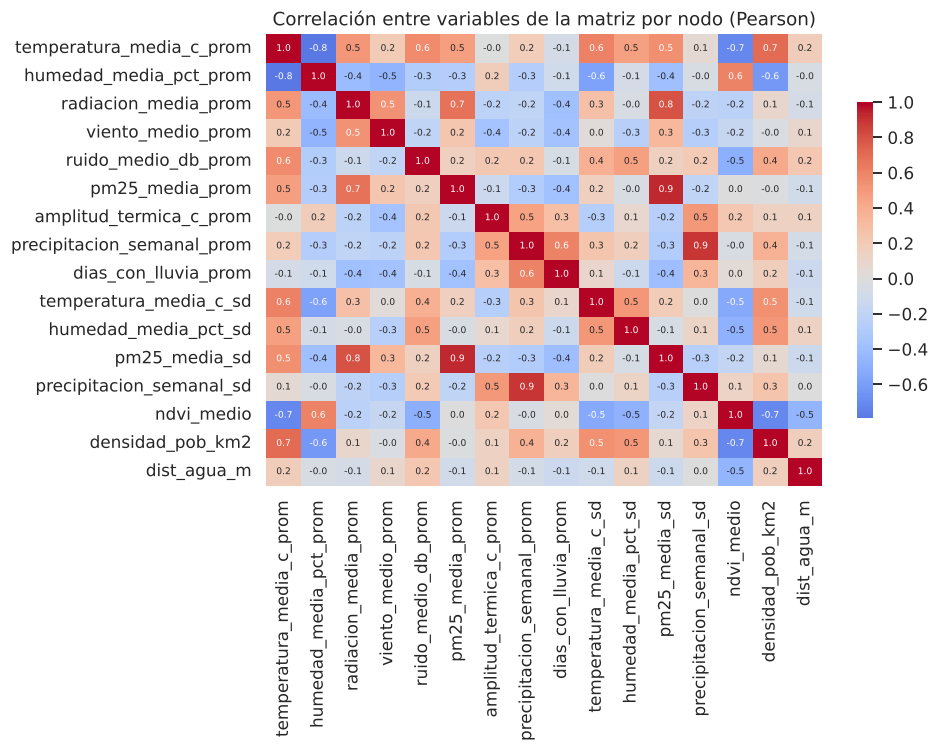

In [4]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(nodos.corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 6}, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Correlación entre variables de la matriz por nodo (Pearson)")
plt.tight_layout(); plt.show()

## 2. Estandarización

K-Means y Ward usan distancia euclídea; sin escalar, `densidad_pob_km2` (miles) dominaría sobre `ndvi_medio` (0–1). `StandardScaler` lleva cada variable a media 0 y desviación 1, de modo que todas pesan igual.

In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(nodos)
Xdf = pd.DataFrame(X, index=nodos.index, columns=nodos.columns)
print("Media ≈ 0:", np.allclose(X.mean(0), 0), "| Desv. ≈ 1:", np.allclose(X.std(0), 1))

Media ≈ 0: True | Desv. ≈ 1: True


## 3. Selección del número de clusters (codo + Silhouette)

Se evalúa *k* = 2…8 con K-Means (50 inicializaciones) y Ward. Con *n* = 17, *k* > 8 no tiene sentido (clusters de 1–2 nodos).

,inercia,sil_kmeans,sil_ward,ARI_km_vs_ward,tam_min_cluster
k,,,,,
2,207.965,0.193,0.193,1.000,7
3,154.362,0.195,0.195,1.000,1
4,131.876,0.125,0.159,0.506,1
5,108.329,0.126,0.126,1.000,1
6,90.896,0.146,0.137,0.789,1
7,77.964,0.116,0.134,0.867,1
8,63.352,0.120,0.120,1.000,1


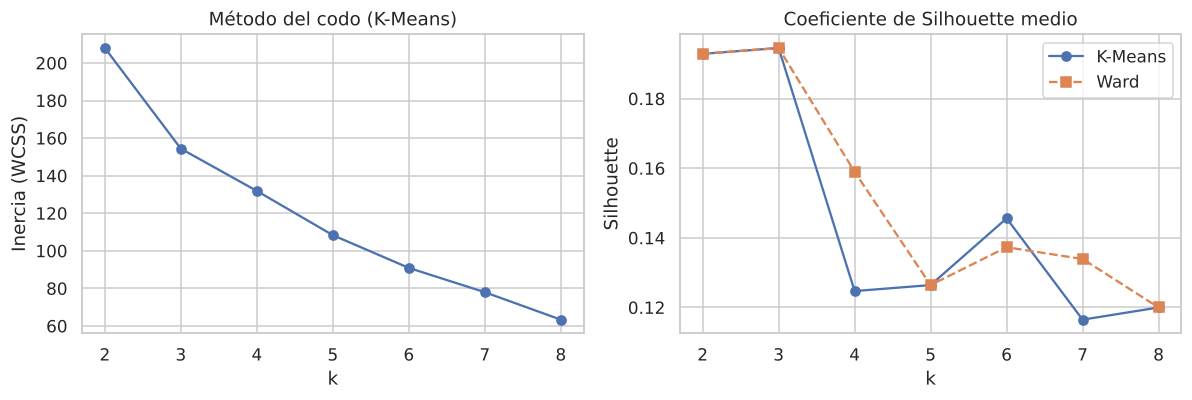

In [6]:
ks = range(2, 9)
res = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    ag = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X)
    res.append(dict(k=k, inercia=km.inertia_,
                    sil_kmeans=silhouette_score(X, km.labels_),
                    sil_ward=silhouette_score(X, ag.labels_),
                    ARI_km_vs_ward=adjusted_rand_score(km.labels_, ag.labels_),
                    tam_min_cluster=np.bincount(km.labels_).min()))
met = pd.DataFrame(res).set_index("k")
display(met.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(met.index, met.inercia, "o-"); ax[0].set(title="Método del codo (K-Means)", xlabel="k", ylabel="Inercia (WCSS)")
ax[1].plot(met.index, met.sil_kmeans, "o-", label="K-Means")
ax[1].plot(met.index, met.sil_ward, "s--", label="Ward")
ax[1].set(title="Coeficiente de Silhouette medio", xlabel="k", ylabel="Silhouette"); ax[1].legend()
plt.tight_layout(); plt.show()

**Lectura de las métricas**

- **Codo:** la inercia cae de forma casi uniforme; no hay un codo nítido. La mayor reducción relativa ocurre de 2→3 y el descenso posterior es gradual.
- **Silhouette:** el máximo está en *k* = 3 (≈0.195) pero es prácticamente idéntico a *k* = 2 (≈0.193). **Todos los valores son < 0.25**, lo que indica estructura **débil**: los grupos son una partición útil, no categorías naturales bien separadas.
- **Concordancia:** K-Means y Ward coinciden exactamente (ARI = 1) en *k* = 2 y 3; divergen en *k* = 4, 6 y 7. Desde *k* = 3 siempre aparece un cluster de un solo nodo.

**Decisión: *k* = 2** como partición principal (empate en Silhouette → se prefiere la solución más parsimoniosa, sin clusters unitarios y con tamaños 10/7). Se reporta *k* = 3 como análisis de sensibilidad: la única diferencia es que aísla al nodo 8.

## 4. Modelado final: K-Means y clustering jerárquico

In [7]:
K = 2
km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(X)
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)

nodos["cluster_kmeans"] = km.labels_
nodos["cluster_ward"]   = ward.labels_

# Renombrar para que 0 sea siempre el cluster menos urbanizado (etiquetas arbitrarias en K-Means)
orden = nodos.groupby("cluster_kmeans")["densidad_pob_km2"].mean().sort_values().index
mapa = {old: new for new, old in enumerate(orden)}
nodos["cluster_kmeans"] = nodos["cluster_kmeans"].map(mapa)
mapa_w = {old: new for new, old in enumerate(nodos.groupby("cluster_ward")["densidad_pob_km2"].mean().sort_values().index)}
nodos["cluster_ward"] = nodos["cluster_ward"].map(mapa_w)

print("ARI K-Means vs Ward:", adjusted_rand_score(nodos.cluster_kmeans, nodos.cluster_ward))
print("Silhouette K-Means:", round(silhouette_score(X, nodos.cluster_kmeans), 3))
for c, g in nodos.groupby("cluster_kmeans"):
    print(f"Cluster {c} (n={len(g)}): nodos {sorted(g.index.tolist())}")

ARI K-Means vs Ward: 1.0
Silhouette K-Means: 0.193
Cluster 0 (n=10): nodos [1, 2, 3, 6, 7, 10, 11, 15, 17, 18]
Cluster 1 (n=7): nodos [4, 5, 8, 12, 13, 14, 16]


Correlación cofenética: 0.615


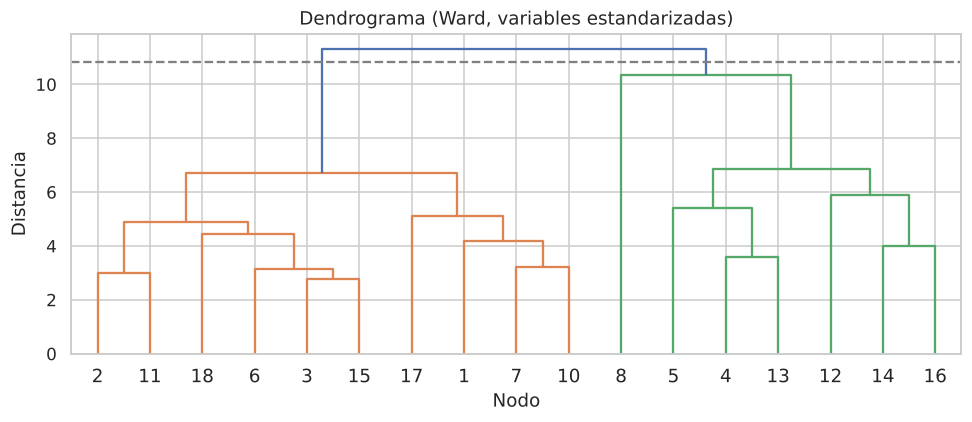

In [8]:
# Dendrograma (Ward) + correlación cofenética
Z = linkage(X, method="ward")
print("Correlación cofenética:", round(cophenet(Z, pdist(X))[0], 3))

fig, ax = plt.subplots(figsize=(9, 4))
thr = (Z[-K, 2] + Z[-(K - 1), 2]) / 2   # corte entre las dos últimas fusiones → K clusters
dendrogram(Z, labels=nodos.index.tolist(), color_threshold=thr, ax=ax)
ax.axhline(thr, ls="--", c="gray"); ax.set(title="Dendrograma (Ward, variables estandarizadas)", xlabel="Nodo", ylabel="Distancia")
plt.tight_layout(); plt.show()

Varianza explicada PC1+PC2: [0.3   0.238] → 0.538


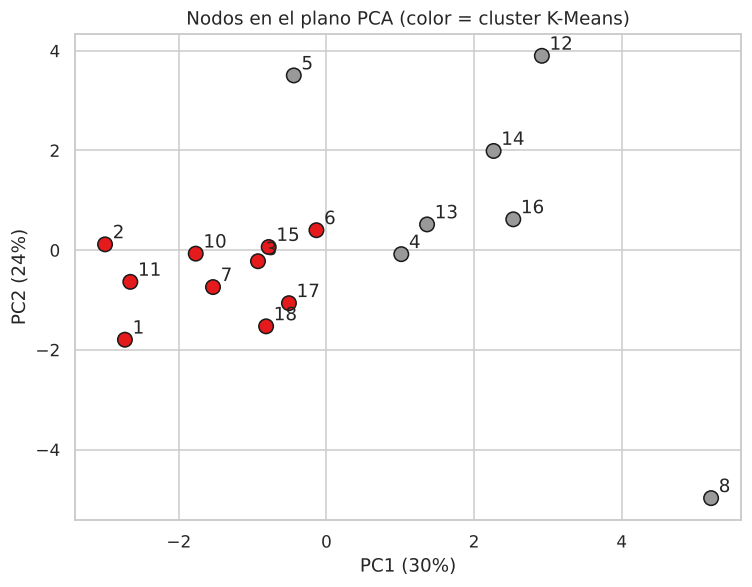

Nodos con silhouette < 0 (mal asignados): [4, 5, 13]


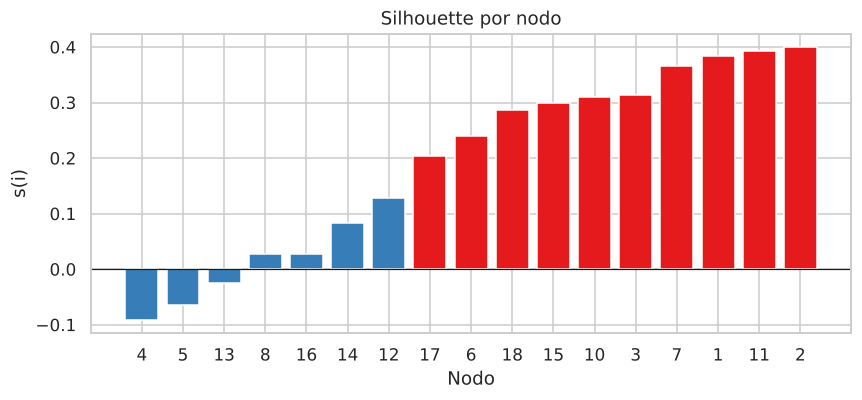

In [9]:
# Proyección PCA (solo visualización)
pca = PCA(n_components=2, random_state=SEED).fit(X)
P = pca.transform(X)
print("Varianza explicada PC1+PC2:", pca.explained_variance_ratio_.round(3), "→", round(pca.explained_variance_ratio_.sum(), 3))

fig, ax = plt.subplots(figsize=(7, 5.5))
sc = ax.scatter(P[:, 0], P[:, 1], c=nodos.cluster_kmeans, cmap="Set1", s=90, edgecolor="k")
for (x, y), n in zip(P, nodos.index): ax.annotate(str(n), (x, y), xytext=(5, 4), textcoords="offset points")
ax.set(title="Nodos en el plano PCA (color = cluster K-Means)", xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.tight_layout(); plt.show()

# Silhouette por nodo
sil = silhouette_samples(X, nodos.cluster_kmeans)
s = pd.Series(sil, index=nodos.index).sort_values()
print("Nodos con silhouette < 0 (mal asignados):", s[s < 0].index.tolist())
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(s.index.astype(str), s.values, color=plt.cm.Set1(nodos.loc[s.index, "cluster_kmeans"]))
ax.axhline(0, c="k", lw=.8); ax.set(title="Silhouette por nodo", xlabel="Nodo", ylabel="s(i)")
plt.tight_layout(); plt.show()

## 5. Interpretación ambiental y biológica

### 5.1 Perfil de los clusters

cluster_kmeans,0,1,diferencia_z
temperatura_media_c_prom,24.23,25.25,1.66
ruido_medio_db_prom,46.58,58.00,1.47
densidad_pob_km2,781.45,5537.59,1.46
temperatura_media_c_sd,1.09,1.13,0.98
pm25_media_sd,4.78,22.31,0.92
pm25_media_prom,10.22,14.58,0.74
precipitacion_semanal_prom,20.43,25.24,0.74
radiacion_media_prom,160.89,190.88,0.68
humedad_media_pct_sd,5.67,5.95,0.65
precipitacion_semanal_sd,29.29,33.46,0.60


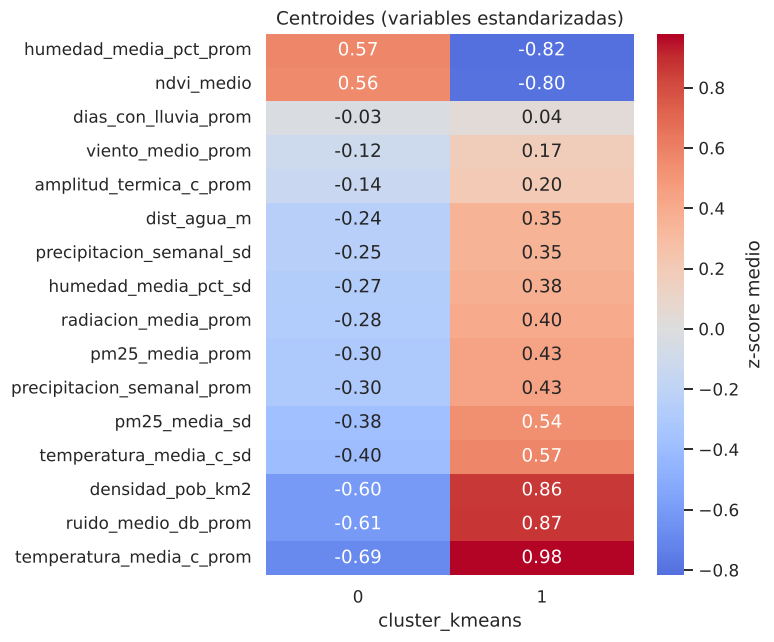

In [10]:
perfil = nodos.groupby("cluster_kmeans").mean().drop(columns="cluster_ward").T
perfil["diferencia_z"] = (Xdf.groupby(nodos.cluster_kmeans).mean().T[1] - Xdf.groupby(nodos.cluster_kmeans).mean().T[0])
display(perfil.round(2).sort_values("diferencia_z", ascending=False))

fig, ax = plt.subplots(figsize=(7, 6))
z = Xdf.groupby(nodos.cluster_kmeans).mean().T.loc[perfil.sort_values("diferencia_z").index]
sns.heatmap(z, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=ax, cbar_kws={"label": "z-score medio"})
ax.set_title("Centroides (variables estandarizadas)"); plt.tight_layout(); plt.show()

**Cluster 0 (n = 10; nodos 1, 2, 3, 6, 7, 10, 11, 15, 17, 18) — "menos urbanizado, más verde, más fresco y húmedo":** baja densidad poblacional (~780 hab/km²), NDVI alto (~0.55), temperatura media menor (~24.2 °C), humedad mayor (~76 %), ruido bajo (~47 dB) y PM2.5 bajo y estable.

**Cluster 1 (n = 7; nodos 4, 5, 8, 12, 13, 14, 16) — "urbano denso, más cálido y seco":** densidad ~5 500 hab/km² (7×), NDVI bajo (~0.43), ~1 °C más cálido, humedad ~3.5 puntos menor, mayor radiación, ruido ~58 dB y PM2.5 más alto con **gran variabilidad** (picos de contaminación). También mayor distancia media a cuerpos de agua.

**Lectura:** el eje principal es un **gradiente urbano–verde** (densidad, NDVI, ruido, PM2.5), acompañado de un efecto tipo **isla de calor** (más temperatura y radiación, menos humedad). `dias_con_lluvia` y `amplitud_termica` casi no discriminan; la precipitación acumulada es algo mayor en el cluster 1 (≈ +5 mm/semana) pero con alta dispersión semanal.

**Ajuste de la partición:** los nodos 4, 5 y 13 tienen Silhouette negativo (quedan más cerca del otro cluster que del propio, ver gráfico) → son nodos de transición; el nodo 8 es un valor extremo (radiación ≈ 319 vs ≈ 173 en promedio) y cobertura de sensores baja.

> Las variables ambientales más diferenciadoras son de **entorno** (densidad, ruido, NDVI, PM2.5), no de clima: el clima varía poco entre nodos de una misma ciudad (CV de temperatura media ≈ 2.5 %).

### 5.2 ¿Difiere el conteo de huevos entre clusters?

               huevos_prom       huevos_mediana       pct_semanas_cero     
                      mean   std           mean   std             mean  std
cluster_kmeans                                                             
0                     59.7  36.0           44.2  34.4             36.7  7.0
1                    107.6  59.1           87.3  53.9             29.2  7.6

Mann-Whitney (unidad = nodo, n=10+7): U=10, p=0.0136
P(nodo de cluster 1 > nodo de cluster 0) = 0.86


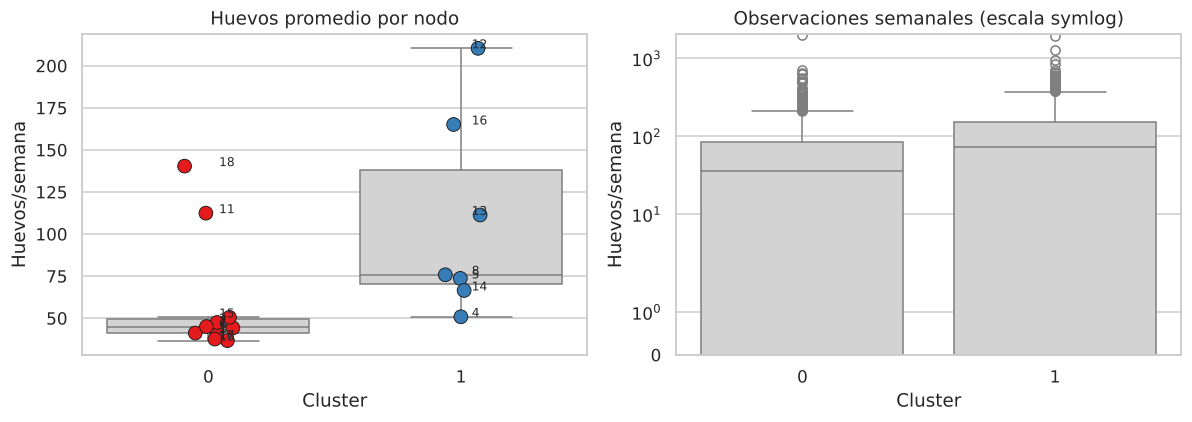

In [11]:
huevos = df.groupby("nodo")["huevos_aedes"].agg(huevos_prom="mean", huevos_mediana="median")
nodos = nodos.join(huevos)
nodos["pct_semanas_cero"] = df.assign(z=df.huevos_aedes.eq(0)).groupby("nodo")["z"].mean() * 100

print(nodos.groupby("cluster_kmeans")[["huevos_prom", "huevos_mediana", "pct_semanas_cero"]].agg(["mean", "std"]).round(1))

g0 = nodos.loc[nodos.cluster_kmeans == 0, "huevos_prom"]; g1 = nodos.loc[nodos.cluster_kmeans == 1, "huevos_prom"]
u = mannwhitneyu(g0, g1, alternative="two-sided")
print(f"\nMann-Whitney (unidad = nodo, n={len(g0)}+{len(g1)}): U={u.statistic:.0f}, p={u.pvalue:.4f}")

# Tamaño de efecto: probabilidad de superioridad (CLES)
cles = (g1.values[:, None] > g0.values[None, :]).mean()
print(f"P(nodo de cluster 1 > nodo de cluster 0) = {cles:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=nodos, x="cluster_kmeans", y="huevos_prom", ax=ax[0], color="lightgray", showfliers=False)
sns.stripplot(data=nodos, x="cluster_kmeans", y="huevos_prom", ax=ax[0], hue="cluster_kmeans", palette="Set1", size=9, edgecolor="k", linewidth=.6, legend=False)
for n, r in nodos.iterrows(): ax[0].annotate(str(n), (r.cluster_kmeans, r.huevos_prom), xytext=(7, 0), textcoords="offset points", fontsize=8)
ax[0].set(title="Huevos promedio por nodo", xlabel="Cluster", ylabel="Huevos/semana")
sns.boxplot(data=df.merge(nodos[["cluster_kmeans"]], left_on="nodo", right_index=True), x="cluster_kmeans", y="huevos_aedes", ax=ax[1], color="lightgray")
ax[1].set_yscale("symlog"); ax[1].set_ylim(bottom=0); ax[1].set(title="Observaciones semanales (escala symlog)", xlabel="Cluster", ylabel="Huevos/semana")
plt.tight_layout(); plt.show()

In [12]:
# Sensibilidad: ¿qué variables se asocian con huevos a nivel de nodo? (Spearman, n=17; exploratorio)
rho = pd.Series({c: spearmanr(nodos[c], nodos["huevos_prom"])[0] for c in Xdf.columns}).sort_values()
pv  = pd.Series({c: spearmanr(nodos[c], nodos["huevos_prom"])[1] for c in Xdf.columns})
tab = pd.DataFrame({"rho": rho, "p_sin_ajustar": pv[rho.index]}).round(3)
display(tab.tail(5)); display(tab.head(5))

,rho,p_sin_ajustar
viento_medio_prom,0.230,0.374
precipitacion_semanal_prom,0.235,0.363
ruido_medio_db_prom,0.387,0.125
temperatura_media_c_prom,0.581,0.014
densidad_pob_km2,0.723,0.001


,rho,p_sin_ajustar
humedad_media_pct_prom,-0.755,0.000
ndvi_medio,-0.397,0.115
pm25_media_sd,-0.306,0.232
dist_agua_m,-0.199,0.445
humedad_media_pct_sd,-0.125,0.633


**Resultado.** Los nodos del cluster 1 (urbano denso) tienen ~**108 huevos/semana** frente a ~**60** del cluster 0 (≈1.8×). La diferencia es significativa con Mann-Whitney sobre medias por nodo (U = 10, p ≈ 0.014), pero el contraste es **exploratorio**: n = 10 vs 7 y el clustering se hizo sobre las mismas variables que luego se asocian al resultado.

**Interpretación biológica (hipótesis, no causalidad).** *Aedes aegypti* es un vector **antropofílico y peridoméstico**: depende de hospedero humano y de recipientes artificiales para oviposición, por lo que la mayor densidad poblacional y la urbanización coinciden con mayor abundancia de huevos. La mayor temperatura (~+1 °C) también favorece un ciclo gonotrófico y de desarrollo larvario más rápido. A nivel de nodo, las asociaciones individuales más fuertes con huevos son `humedad_media_pct` (ρ ≈ −0.75), `densidad_pob_km2` (ρ ≈ +0.72) y `temperatura_media_c` (ρ ≈ +0.58). La humedad es difícil de interpretar por separado porque es inversa a la temperatura y probablemente refleja el mismo gradiente urbano (isla de calor); con 16 pruebas y n = 17 estos p-valores no están ajustados y son solo orientativos.

**Heterogeneidad intra-cluster:** en el cluster 1, los nodos 12 (≈210), 16 (≈165) y 13 (≈111) concentran la abundancia, mientras que 4 (≈51), 14 (≈66) y 8 (≈76) se parecen al cluster 0. A la inversa, los nodos 18 (≈140) y 11 (≈112) del cluster 0 —poco urbanizados— tienen conteos altos. Esos contraejemplos muestran que el perfil ambiental agrupado **no basta** para predecir el conteo por nodo. Además, el cluster 1 tiene menos semanas sin huevos (≈29 % vs ≈37 %).

## 6. Robustez y análisis de sensibilidad

Con *n* = 17 y 16 variables, se verifica si la partición depende de decisiones arbitrarias: (a) usar solo promedios + externas, (b) *k* = 3, (c) remover un nodo a la vez (*leave-one-out*), (d) bootstrap de nodos.

In [13]:
base = nodos["cluster_kmeans"].values

# (a) solo promedios + externas (sin desviaciones)
cols_a = [c for c in nodos.columns if (c.endswith("_prom") or c in ext.columns) and c != "nodo"]
Xa = StandardScaler().fit_transform(nodos[cols_a])
la = KMeans(2, n_init=50, random_state=SEED).fit_predict(Xa)
print(f"(a) Sin desviaciones: ARI vs partición base = {adjusted_rand_score(base, la):.2f} | silhouette = {silhouette_score(Xa, la):.3f}")

# (b) k = 3
k3 = KMeans(3, n_init=50, random_state=SEED).fit(X).labels_
print("(b) k=3 tamaños:", np.bincount(k3), "| nodos aislados:", [n for c in range(3) for n in nodos.index[k3 == c] if (k3 == c).sum() == 1])
print("    huevos prom por cluster (k=3):", nodos.groupby(k3).huevos_prom.mean().round(1).tolist(),
      "| Kruskal p =", round(kruskal(*[nodos.huevos_prom[k3 == c] for c in range(3)]).pvalue, 3))

# (c) leave-one-out
aris = []
for i in range(len(nodos)):
    m_ = np.ones(len(nodos), bool); m_[i] = False
    Xi = StandardScaler().fit_transform(nodos.iloc[:, :X.shape[1]][m_])
    li = KMeans(2, n_init=50, random_state=SEED).fit_predict(Xi)
    aris.append(adjusted_rand_score(base[m_], li))
print(f"(c) Leave-one-out ARI: media={np.mean(aris):.2f}, mín={np.min(aris):.2f}; nodo cuya salida más cambia la partición: {nodos.index[int(np.argmin(aris))]}")

# (d) bootstrap de nodos (ARI sobre nodos remuestreados, comparado con la partición base de esos nodos)
rng = np.random.default_rng(SEED); b = []
for _ in range(300):
    idx = rng.choice(len(nodos), len(nodos), replace=True)
    if len(np.unique(idx)) < 6: continue
    Xb = StandardScaler().fit_transform(nodos.iloc[:, :X.shape[1]].iloc[idx])
    lb = KMeans(2, n_init=10, random_state=SEED).fit_predict(Xb)
    b.append(adjusted_rand_score(base[idx], lb))
print(f"(d) Bootstrap (300): ARI mediana={np.median(b):.2f}, IC90%=[{np.percentile(b,5):.2f}, {np.percentile(b,95):.2f}]")

(a) Sin desviaciones: ARI vs partición base = 1.00 | silhouette = 0.210
(b) k=3 tamaños: [ 6 10  1] | nodos aislados: [8]
    huevos prom por cluster (k=3): [113.0, 59.7, 75.8] | Kruskal p = 0.051


(c) Leave-one-out ARI: media=0.96, mín=0.75; nodo cuya salida más cambia la partición: 1


(d) Bootstrap (300): ARI mediana=0.56, IC90%=[-0.02, 1.00]


## 7. Limitaciones

| Limitación | Consecuencia | Mitigación aplicada / recomendada |
|---|---|---|
| **n = 17 nodos** (no 18; falta el nodo 9) frente a **16 variables** | Relación n/p ≈ 1: alta dimensionalidad relativa, centroides inestables y distancias poco discriminantes | Se descartaron variables redundantes; se recomienda reducir a ≤ 6–8 variables o usar PCA previo |
| **Silhouette < 0.25** y codo sin quiebre claro | La estructura es un **gradiente continuo** urbano–verde, no grupos naturales | Interpretar los clusters como categorías operativas, no taxonomía |
| **Estabilidad** | Leave-one-out: ARI medio ≈ 0.96 (mín 0.75), partición razonablemente estable; bootstrap de nodos: ARI mediana ≈ 0.56 con IC90 ≈ [−0.02, 1.00] → **inestable** ante remuestreo; correlación cofenética 0.62 (ajuste jerárquico moderado) | Reportar sensibilidad; no sobreinterpretar la frontera (nodos 4, 5, 13 con Silhouette < 0) |
| **Tamaño de muestra del test de huevos** (10 vs 7 nodos) | p ≈ 0.014 sin corrección y circularidad parcial (las mismas variables definen clusters y se asocian con huevos) → riesgo de falsos positivos | Tratar como exploratorio; validar con modelo a nivel semanal con efectos aleatorios por nodo |
| **Pseudo-replicación** | Las 169 semanas/nodo no son independientes (autocorrelación temporal y espacial) | Se contrasta con una observación por nodo (media), no por semana |
| **Resumen estático** | Promedios por nodo borran la dinámica estacional y los rezagos que sí afectan a *Aedes* | Complementar con modelos de series de tiempo (Punto de modelado supervisado) |
| **Calidad desigual de datos** | Nodos 8 y 13 con cobertura media de sensores ≈ 70–77 % vs > 89 % del resto; el nodo 8 es el que k = 3 aísla | Verificar si su singularidad es ambiental o un artefacto de cobertura |
| **Variables externas estáticas** | NDVI, densidad y distancia al agua son una sola cifra por nodo (sin variación temporal) y su escala espacial/fecha de captura no están documentadas aquí | Documentar fuente y buffer con la Persona 1 |
| **Clima casi homogéneo** | Poca variación de temperatura/humedad entre nodos (CV ≈ 2–3 %) → el clustering lo dirige el entorno urbano, no el clima | Usar interpretaciones ambientales con cautela |

## 8. Conclusiones

1. Los 17 nodos se separan en **dos perfiles**: menos urbanizado y más verde (10 nodos) y urbano denso, más cálido y ruidoso (7 nodos). K-Means y Ward producen la **misma partición** (ARI = 1).
2. La separación es **débil** (Silhouette ≈ 0.19): describe un gradiente, no grupos discretos.
3. El cluster urbano denso muestra **~1.8× más huevos por semana**, consistente con la biología antropofílica de *Aedes aegypti*; la evidencia es **exploratoria** por *n* = 17 (efecto: P(nodo del cluster 1 > nodo del cluster 0) ≈ 0.86; p ≈ 0.014 sin corrección).
4. La variabilidad de huevos **dentro** de cada cluster es grande: el perfil ambiental por nodo es insuficiente como predictor y debe integrarse con la dinámica temporal en el modelado supervisado.

In [14]:
# Exportar asignaciones para otros puntos del proyecto
out = nodos[["cluster_kmeans", "cluster_ward", "huevos_prom", "huevos_mediana", "pct_semanas_cero"]].reset_index()
out.to_csv("clusters_nodos.csv", index=False)
out

,nodo,cluster_kmeans,cluster_ward,huevos_prom,huevos_mediana,pct_semanas_cero
0,1,0,0,41.715976,27.0,40.828402
1,2,0,0,47.431953,28.0,40.236686
2,3,0,0,41.147929,28.0,41.420118
3,4,1,1,50.816568,37.0,38.461538
4,5,1,1,73.633136,69.0,30.769231
5,6,0,0,44.195266,36.0,35.502959
6,7,0,0,45.000000,35.0,35.502959
7,8,1,1,75.781065,40.0,36.686391
8,10,0,0,36.650888,23.0,42.603550
9,11,0,0,112.411243,104.0,26.627219
